# 01 · Análisis exploratorio y detección de quejas

**Proyecto:** Triaje de quejas en reseñas de e-commerce (PLN + aprendizaje no supervisado)
**Dataset:** *Women's E-Commerce Clothing Reviews* (Kaggle)

## Objetivo del cuaderno
1. Cargar el dataset crudo y describir su estructura (dimensiones, tipos, nulos, duplicados).
2. Analizar la distribución de calificaciones (`Rating`) y de recomendación (`Recommended IND`).
3. **Definir un criterio de "queja" combinando varias señales**, no solo el rating bajo y **sin** una
   lista de palabras negativas elegida a mano (eso haría circular el agrupamiento posterior con K-means).
4. Guardar el subconjunto de reseñas-queja en `datos/procesados/resenas_filtradas.csv`.

> Reproducibilidad: se fija `random_state=42` en todo lo que lo admita. El criterio de queja es una
> heurística de **filtrado previo**, independiente del modelo no supervisado; no usa las etiquetas de
> clúster ni palabras elegidas manualmente.

In [1]:
# Librerías permitidas: pandas, numpy, nltk, scikit-learn, matplotlib, joblib, jupyterlab
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

SEMILLA = 42  # semilla global para reproducibilidad

# Recurso de NLTK necesario para el análisis de sentimiento (VADER)
nltk.download("vader_lexicon", quiet=True)


def encontrar_raiz() -> Path:
    """Localiza la raíz del proyecto buscando hacia arriba las carpetas 'datos' y 'modelos'.
    Esto permite ejecutar el cuaderno tanto desde 'cuadernos/' como desde la raíz."""
    actual = Path.cwd()
    for candidata in [actual, *actual.parents]:
        if (candidata / "datos").is_dir() and (candidata / "modelos").is_dir():
            return candidata
    return actual


RAIZ = encontrar_raiz()
RUTA_CRUDO = RAIZ / "datos" / "crudos" / "Womens Clothing E-Commerce Reviews.csv"
RUTA_FILTRADAS = RAIZ / "datos" / "procesados" / "resenas_filtradas.csv"
print("Raíz del proyecto:", RAIZ)
print("CSV crudo:", RUTA_CRUDO.name, "| existe:", RUTA_CRUDO.exists())

Raíz del proyecto: /home/diegootm/Documentos/triaje-quejas-resenas-ecommerce
CSV crudo: Womens Clothing E-Commerce Reviews.csv | existe: True


## 1. Carga del dataset

Al cargar el CSV se descarta cualquier columna de índice sin nombre (tipo `Unnamed: 0`), que solo
replica el índice de la fila y no aporta información.

In [2]:
df = pd.read_csv(RUTA_CRUDO)

# Descartar columnas de índice sin nombre (p. ej. "Unnamed: 0")
columnas_sin_nombre = [c for c in df.columns if c.startswith("Unnamed")]
df = df.drop(columns=columnas_sin_nombre)
print("Columnas descartadas por ser índice sin nombre:", columnas_sin_nombre)
print("Dimensiones del dataset:", df.shape)
df.head()

Columnas descartadas por ser índice sin nombre: ['Unnamed: 0']
Dimensiones del dataset: (23486, 10)


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


## 2. Tipos de datos, valores nulos y duplicados

In [3]:
print("=== Tipos de datos ===")
print(df.dtypes)
print("\n=== Valores nulos por columna ===")
print(df.isna().sum())
print("\n=== Filas duplicadas (completas) ===")
print("Duplicados:", df.duplicated().sum())

=== Tipos de datos ===
Clothing ID                 int64
Age                         int64
Title                      object
Review Text                object
Rating                      int64
Recommended IND             int64
Positive Feedback Count     int64
Division Name              object
Department Name            object
Class Name                 object
dtype: object

=== Valores nulos por columna ===
Clothing ID                   0
Age                           0
Title                      3810
Review Text                 845
Rating                        0
Recommended IND               0
Positive Feedback Count       0
Division Name                14
Department Name              14
Class Name                   14
dtype: int64

=== Filas duplicadas (completas) ===
Duplicados: 21


La columna clave para el análisis de texto es `Review Text`. Las reseñas sin texto no sirven para el
agrupamiento posterior (TF-IDF necesita texto), así que se trabajará con las filas que **sí** tienen reseña.

In [4]:
n_sin_texto = df["Review Text"].isna().sum()
print(f"Reseñas sin 'Review Text': {n_sin_texto} de {len(df)} ({n_sin_texto/len(df):.1%})")

# Conservamos solo filas con texto de reseña (necesario para VADER y TF-IDF)
df = df.dropna(subset=["Review Text"]).reset_index(drop=True)
print("Dimensiones tras eliminar reseñas sin texto:", df.shape)

Reseñas sin 'Review Text': 845 de 23486 (3.6%)
Dimensiones tras eliminar reseñas sin texto: (22641, 10)


## 3. Distribución de calificaciones y de recomendación

=== Distribución de Rating (1 a 5) ===
Rating
1      821
2     1549
3     2823
4     4908
5    12540
Name: count, dtype: int64

=== Distribución de Recommended IND (0 = no recomienda, 1 = recomienda) ===
Recommended IND
0     4101
1    18540
Name: count, dtype: int64


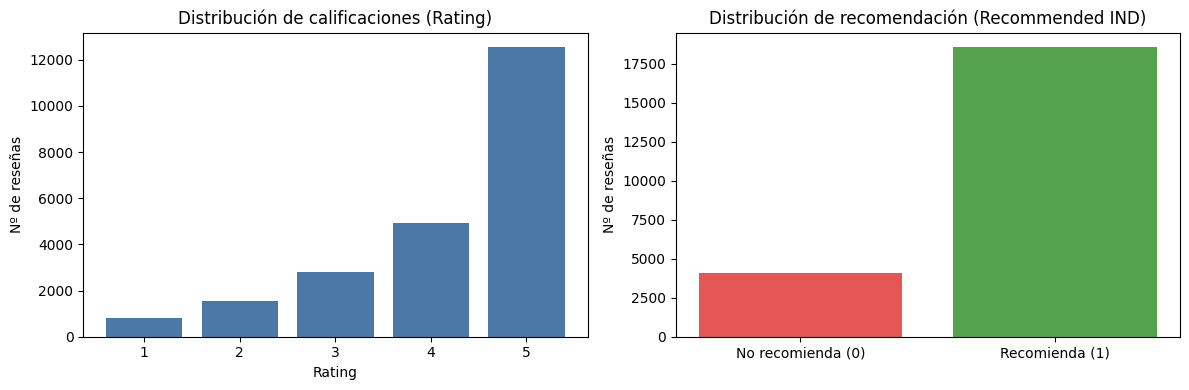

In [5]:
conteo_rating = df["Rating"].value_counts().sort_index()
conteo_reco = df["Recommended IND"].value_counts().sort_index()
print("=== Distribución de Rating (1 a 5) ===")
print(conteo_rating)
print("\n=== Distribución de Recommended IND (0 = no recomienda, 1 = recomienda) ===")
print(conteo_reco)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].bar(conteo_rating.index.astype(str), conteo_rating.values, color="#4C78A8")
ejes[0].set_title("Distribución de calificaciones (Rating)")
ejes[0].set_xlabel("Rating"); ejes[0].set_ylabel("Nº de reseñas")
ejes[1].bar(["No recomienda (0)", "Recomienda (1)"], conteo_reco.values, color=["#E45756", "#54A24B"])
ejes[1].set_title("Distribución de recomendación (Recommended IND)")
ejes[1].set_ylabel("Nº de reseñas")
plt.tight_layout(); plt.show()

**Observación.** El dataset está muy sesgado hacia reseñas positivas: la mayoría son `Rating` 4–5 y
`Recommended IND = 1`. Por eso una queja no puede detectarse solo con el rating; conviene combinar señales.

## 4. Criterio para identificar reseñas con queja

No basta con "rating bajo", y **tampoco** queremos una lista de palabras negativas hecha a mano, porque
eso introduciría de antemano los términos que luego K-means debería *descubrir* (resultado circular).

Combinamos **tres señales objetivas**:

| Señal | Qué captura |
|-------|-------------|
| `Rating <= 2` | Insatisfacción explícita en la calificación. |
| `Recommended IND == 0` | El cliente declara que **no** recomienda la prenda. |
| **Sentimiento negativo (VADER)** | Negatividad **en el texto**, útil para casos como *"5 estrellas pero la talla vino mal"* (buena nota pero queja escrita). |

VADER (del módulo `nltk.sentiment`) es un analizador de sentimiento **basado en léxico y reglas**, no
entrenado sobre este dataset, por lo que no depende de etiquetas nuestras ni de palabras que hayamos elegido.
Devuelve un puntaje `compound` en el rango **[-1, 1]**.

Estadísticos del puntaje VADER (compound):
count    22641.000000
mean         0.736021
std          0.371657
min         -0.956200
25%          0.709600
50%          0.889600
75%          0.949600
max          0.995900
Name: vader_compound, dtype: float64


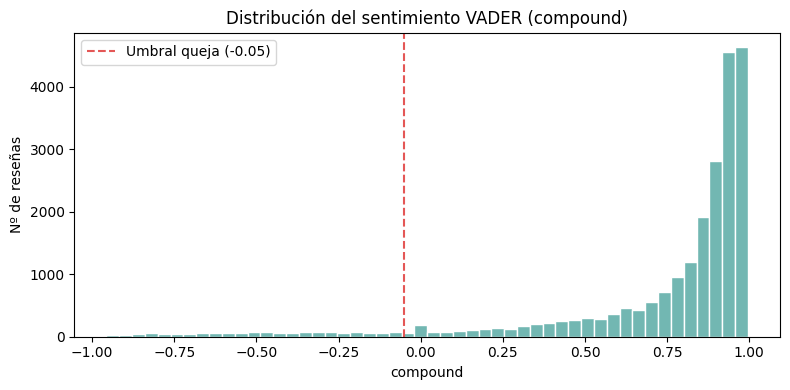

In [6]:
sia = SentimentIntensityAnalyzer()

# Puntaje compuesto de sentimiento sobre el texto de la reseña
df["vader_compound"] = df["Review Text"].astype(str).apply(lambda t: sia.polarity_scores(t)["compound"])

print("Estadísticos del puntaje VADER (compound):")
print(df["vader_compound"].describe())

plt.figure(figsize=(8, 4))
plt.hist(df["vader_compound"], bins=50, color="#72B7B2", edgecolor="white")
plt.axvline(-0.05, color="#E45756", linestyle="--", label="Umbral queja (-0.05)")
plt.title("Distribución del sentimiento VADER (compound)")
plt.xlabel("compound"); plt.ylabel("Nº de reseñas"); plt.legend()
plt.tight_layout(); plt.show()

### Justificación del umbral de sentimiento

La convención estándar de VADER clasifica un texto como **negativo** cuando `compound <= -0.05`
(y positivo cuando `>= 0.05`). Adoptamos ese mismo umbral, `compound <= -0.05`, por tres razones:

1. **Es un criterio documentado y reproducible**, no un número elegido ad hoc para este dataset.
2. Es **inclusivo con la negatividad leve**: preferimos capturar de más en la etapa de *filtrado* (es
   un triaje) antes que descartar quejas suaves pero reales.
3. Comparado con umbrales más estrictos (−0.2, −0.3), la diferencia en el total de quejas es pequeña,
   pero −0.05 es el que **más casos "texto negativo pese a buena calificación"** rescata, que es
   justamente el aporte diferencial de VADER frente a `Rating`/`Recommended`.

Una reseña se marca como **queja** si cumple **al menos una** de las tres señales.

In [7]:
UMBRAL_VADER = -0.05

df["calif_baja"] = df["Rating"] <= 2
df["no_recomienda"] = df["Recommended IND"] == 0
df["sent_negativo"] = df["vader_compound"] <= UMBRAL_VADER
df["es_queja"] = df["calif_baja"] | df["no_recomienda"] | df["sent_negativo"]

total = len(df)
print(f"Reseñas marcadas como queja: {df['es_queja'].sum()} de {total} ({df['es_queja'].mean():.1%})\n")
print("Aporte de cada señal (puede solaparse):")
print(f"  - Rating <= 2            : {df['calif_baja'].sum()}")
print(f"  - Recommended IND == 0   : {df['no_recomienda'].sum()}")
print(f"  - Sentimiento negativo   : {df['sent_negativo'].sum()}")

# Valor añadido de VADER: quejas que NI el rating NI la recomendación detectarían
solo_vader = df["sent_negativo"] & ~df["calif_baja"] & ~df["no_recomienda"]
print(f"\nQuejas detectadas SOLO por VADER (rating alto y recomienda, pero texto negativo): {solo_vader.sum()}")

Reseñas marcadas como queja: 4675 de 22641 (20.6%)

Aporte de cada señal (puede solaparse):
  - Rating <= 2            : 2370
  - Recommended IND == 0   : 4101
  - Sentimiento negativo   : 1377

Quejas detectadas SOLO por VADER (rating alto y recomienda, pero texto negativo): 465


**Verificación del caso "5 estrellas pero con queja".** Mostramos ejemplos de reseñas con
`Rating` alto (4–5) que recomiendan la prenda pero cuyo **texto** es negativo: son las que solo VADER
rescata y las que justifican combinar señales.

In [8]:
ejemplos = df.loc[solo_vader, ["Rating", "Recommended IND", "vader_compound", "Review Text"]]
ejemplos = ejemplos.sort_values("vader_compound").head(5)
for _, fila in ejemplos.iterrows():
    print(f"[Rating={fila['Rating']} | Recomienda={fila['Recommended IND']} | VADER={fila['vader_compound']:.3f}]")
    print(" ", fila["Review Text"][:300], "\n")

[Rating=3 | Recomienda=1 | VADER=-0.942]
  I bought this jumpsuit in both fabrics. i adored the fit and feel of both, but sadly, the graphic fabric was not handled well in the construction. three examples: a thin white piece along one leg seam made it look like a hole; mismatched large pieces of white in the crotch area looked sloppy and wro 

[Rating=3 | Recomienda=1 | VADER=-0.933]
  Took another reviewer's advice and sized up to an xl. unfortunately it grabbed around my midsection and wasn't attractive. love the color. and it's dreamy soft. the sleeves are attractive on less than toned arms. my problem was with the side view which emphasized my tummy (it clings) and you could s 

[Rating=5 | Recomienda=1 | VADER=-0.914]
  I tried these on at the store and thought the color, texture and style was very nice, but i needed the petite length. so i came online but was disappointed to see that the style is sold out in petite! darn. the regular length hits me just above the ankle, so i supp

## 5. Guardado del subconjunto filtrado

In [9]:
# Conservamos columnas útiles para las etapas siguientes (texto, metadatos de producto y señales)
columnas_guardar = [
    "Clothing ID", "Age", "Title", "Review Text", "Rating", "Recommended IND",
    "Positive Feedback Count", "Division Name", "Department Name", "Class Name",
    "vader_compound", "calif_baja", "no_recomienda", "sent_negativo", "es_queja",
]
resenas_queja = df.loc[df["es_queja"], columnas_guardar].reset_index(drop=True)

RUTA_FILTRADAS.parent.mkdir(parents=True, exist_ok=True)
resenas_queja.to_csv(RUTA_FILTRADAS, index=False, encoding="utf-8")
print(f"Guardadas {len(resenas_queja)} reseñas-queja en:\n  {RUTA_FILTRADAS}")
resenas_queja.head()

Guardadas 4675 reseñas-queja en:
  /home/diegootm/Documentos/triaje-quejas-resenas-ecommerce/datos/procesados/resenas_filtradas.csv


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name,vader_compound,calif_baja,no_recomienda,sent_negativo,es_queja
0,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses,0.9427,False,True,False,True
1,1080,49,Not for the very petite,"I love tracy reese dresses, but this one is no...",2,0,4,General,Dresses,Dresses,0.9419,True,True,False,True
2,858,39,"Shimmer, surprisingly goes with lots","I ordered this in carbon for store pick up, an...",4,1,4,General Petite,Tops,Knits,-0.0909,False,False,True,True
3,1077,34,Such a fun dress!,"I'm 5""5' and 125 lbs. i ordered the s petite t...",5,1,0,General,Dresses,Dresses,-0.3724,False,False,True,True
4,1077,53,Dress looks like it's made of cheap material,Dress runs small esp where the zipper area run...,3,0,14,General,Dresses,Dresses,0.3578,False,True,False,True


## Conclusiones del cuaderno 01

- El dataset tiene fuerte sesgo positivo, por lo que detectar quejas requiere **combinar señales** y no
  fiarse solo de la calificación.
- El criterio final de queja = `Rating<=2` **o** `Recommended IND==0` **o** `VADER compound<=-0.05`.
- VADER aporta valor real: rescata reseñas con **texto negativo pese a buena calificación**, sin usar
  listas de palabras elegidas a mano (evitando circularidad con el agrupamiento posterior).
- El subconjunto de quejas queda en `datos/procesados/resenas_filtradas.csv`, listo para el
  preprocesamiento del cuaderno 02.